## Part 1 - 2016 Election Data

## 1(a) Load Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

raw = pd.read_csv("A2016.csv")
print(raw.shape)
raw.head()

(3234, 10)


,FIPS,County,DEM,GOP,MedianIncome,MigraRate,BirthRate,DeathRate,BachelorRate,UnemploymentRate
0,1001,"Autauga County, AL",5908.0,18110.0,54487.0,5.3,12.2,10.0,27.7,5.1
1,1003,"Baldwin County, AL",18409.0,72780.0,56460.0,21.5,11.2,9.8,31.3,5.3
2,1005,"Barbour County, AL",4848.0,5431.0,32884.0,-18.2,10.6,10.8,12.2,8.3
3,1007,"Bibb County, AL",1874.0,6733.0,43079.0,-0.8,12.1,10.8,11.5,6.4
4,1009,"Blount County, AL",2150.0,22808.0,47213.0,-1.0,12.2,11.2,12.6,5.4


In [15]:
%pip install seaborn
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------  11.3/11.3 MB 71.7 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 62.4 MB/s  0:00:00

   ---------------------------------------- 0/6 [wrapt]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
PREDICTORS = ["MedianIncome", "MigraRate", "BirthRate", "DeathRate", "BachelorRate", "UnemploymentRate",
              "TotalVotes"]

# new predictor: total two-party votes cast in the county
raw["TotalVotes"] = raw["DEM"] + raw["GOP"]

no_votes = raw[raw["DEM"].isna() | raw["GOP"].isna()]
state_abbr = no_votes["County"].str[-2:]
print(f"rows without vote counts: {len(no_votes)}")
print("  by state/territory:", state_abbr.value_counts().to_dict())

df = raw.dropna(subset=["DEM", "GOP"] + PREDICTORS).copy()
df["DemShare"] = df["DEM"] / (df["DEM"] + df["GOP"])
df["state"] = df["FIPS"] // 1000            # first two FIPS digits = state code (used in Section 9)

n = len(df)
print(f"\ncomplete-case sample: n = {n} counties in {df['state'].nunique()} states (incl. DC)")
df[["County", "DEM", "GOP", "DemShare"] + PREDICTORS].head()

rows without vote counts: 122
  by state/territory: {'PR': 78, 'AK': 29, 'AS': 5, 'MP': 4, 'VI': 3, 'HI': 1, 'VA': 1, 'GU': 1}

complete-case sample: n = 3111 counties in 50 states (incl. DC)


,County,DEM,GOP,DemShare,MedianIncome,MigraRate,BirthRate,DeathRate,BachelorRate,UnemploymentRate,TotalVotes
0,"Autauga County, AL",5908.0,18110.0,0.245982,54487.0,5.3,12.2,10.0,27.7,5.1,24018.0
1,"Baldwin County, AL",18409.0,72780.0,0.201877,56460.0,21.5,11.2,9.8,31.3,5.3,91189.0
2,"Barbour County, AL",4848.0,5431.0,0.471641,32884.0,-18.2,10.6,10.8,12.2,8.3,10279.0
3,"Bibb County, AL",1874.0,6733.0,0.217730,43079.0,-0.8,12.1,10.8,11.5,6.4,8607.0
4,"Blount County, AL",2150.0,22808.0,0.086145,47213.0,-1.0,12.2,11.2,12.6,5.4,24958.0


In [4]:
fraction_counties = (df["DemShare"] > 0.5).mean()

fraction_votes = df["DEM"].sum() / df["TotalVotes"].sum()

print("Fraction of counties won by DEM:", fraction_counties)
print("Fraction of votes cast for DEM:", fraction_votes)

Fraction of counties won by DEM: 0.1562198649951784
Fraction of votes cast for DEM: 0.5027831032767607


## 1(b): Histogram and vote shares

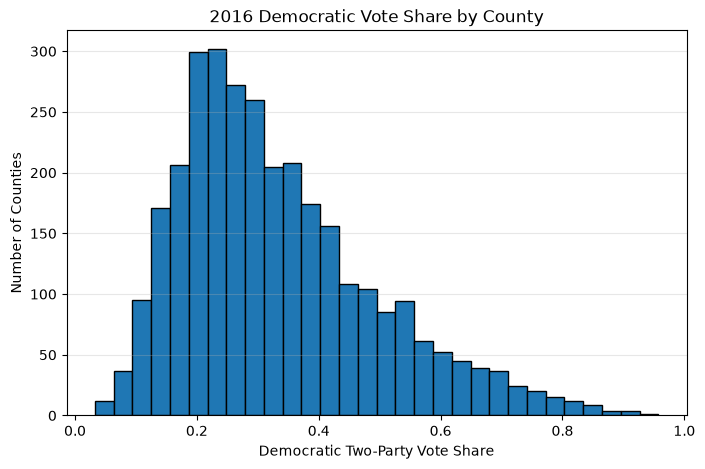

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["DemShare"], bins=30, edgecolor="black")

plt.xlabel("Democratic Two-Party Vote Share")
plt.ylabel("Number of Counties")
plt.title("2016 Democratic Vote Share by County")

plt.grid(axis="y", alpha=0.3)
plt.show()

### 1(b): Democratic Vote Share Analysis

The histogram illustrates the distribution of Democratic two-party vote share across U.S. counties in the 2016 election.

The fraction of counties where Democrats received more than 50% of the two-party vote was approximately **15.62%**, while the fraction of all two-party votes cast for Democrats was approximately **50.28%**.

This large difference occurs because counties vary significantly in population and total votes cast. The fraction of counties won gives each county equal weight, regardless of its size, whereas the overall Democratic vote share accounts for the number of votes cast in each county. Therefore, Democrats could win a relatively small proportion of counties while receiving approximately half of the total two-party votes.

## 1(c) Correlation matrix

In [12]:
# Create LogTotalVotes
df["LogTotalVotes"] = np.log10(df["TotalVotes"])

# Use the seven predictors required by the assignment
predictors = [
    "MedianIncome",
    "MigraRate",
    "BirthRate",
    "DeathRate",
    "BachelorRate",
    "UnemploymentRate",
    "LogTotalVotes"
]

# Compute correlation matrix
columns = predictors + ["DemShare"]

corr_matrix = df[columns].corr()

print(corr_matrix)

                  MedianIncome  MigraRate  BirthRate  DeathRate  BachelorRate  \
MedianIncome          1.000000   0.181037   0.002274  -0.550851      0.708863   
MigraRate             0.181037   1.000000  -0.198965  -0.144478      0.254997   
BirthRate             0.002274  -0.198965   1.000000  -0.227565     -0.068790   
DeathRate            -0.550851  -0.144478  -0.227565   1.000000     -0.506922   
BachelorRate          0.708863   0.254997  -0.068790  -0.506922      1.000000   
UnemploymentRate     -0.465232  -0.158547  -0.016120   0.216383     -0.411079   
LogTotalVotes         0.433151   0.233210   0.047763  -0.396749      0.512769   
DemShare              0.182313   0.032771   0.022056  -0.324008      0.461307   

                  UnemploymentRate  LogTotalVotes  DemShare  
MedianIncome             -0.465232       0.433151  0.182313  
MigraRate                -0.158547       0.233210  0.032771  
BirthRate                -0.016120       0.047763  0.022056  
DeathRate             

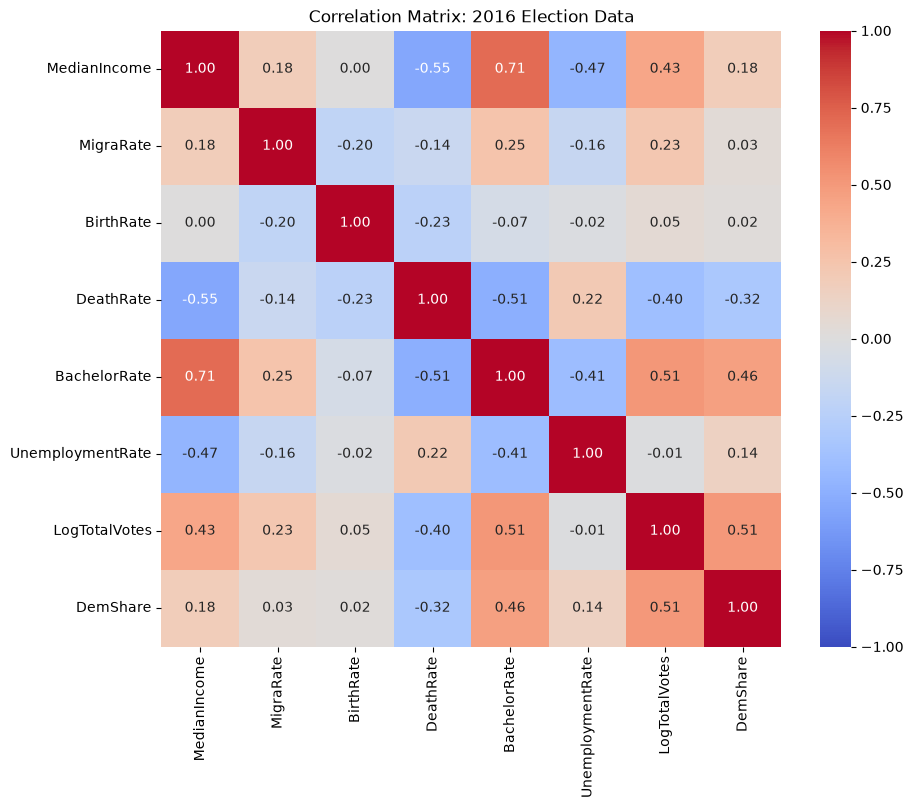

In [13]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix: 2016 Election Data")
plt.show()

### 1(c): Correlation Matrix Analysis

The correlation matrix shows that LogTotalVotes (r = 0.51) and BachelorRate (r = 0.46) have the strongest positive correlations with Democratic two-party vote share. This suggests that counties with more total votes and higher bachelor's degree attainment tend to have higher Democratic vote shares.

DeathRate has a moderate negative correlation with Democratic vote share (r = -0.32), while MedianIncome (r = 0.18) and UnemploymentRate (r = 0.14) show weak positive correlations. MigraRate (r = 0.03) and BirthRate (r = 0.02) show almost no linear correlation with the response.

Among the predictors, MedianIncome and BachelorRate are strongly positively correlated (r = 0.71). MedianIncome and DeathRate are negatively correlated (r = -0.55), as are BachelorRate and DeathRate (r = -0.51). Some predictor pairs, such as MedianIncome and BirthRate, have almost no linear correlation.

These results indicate associations between county characteristics and election outcomes, but correlation alone does not establish causation.

## 1(d) Simple linear regression


--- MedianIncome ---
Slope: 0.000002
P-value: 1.17482e-24
R-squared: 0.0332


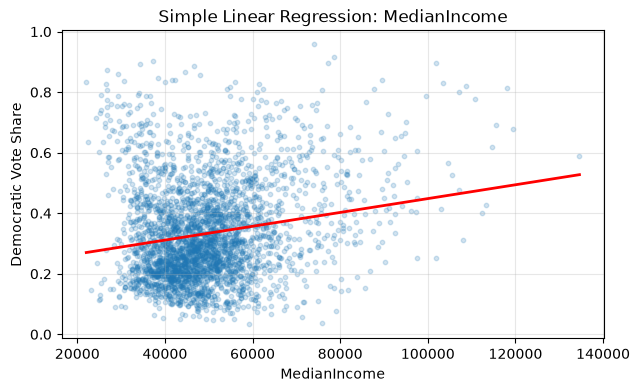


--- MigraRate ---
Slope: 0.000402
P-value: 0.0676065
R-squared: 0.0011


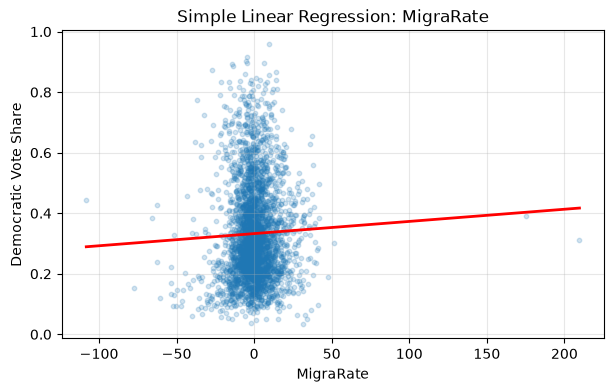


--- BirthRate ---
Slope: 0.001398
P-value: 0.218757
R-squared: 0.0005


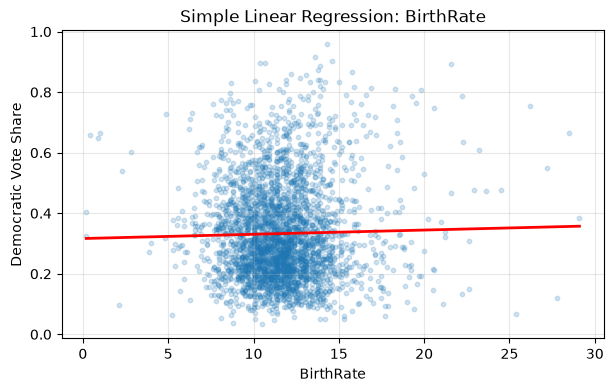


--- DeathRate ---
Slope: -0.018280
P-value: 5.85003e-77
R-squared: 0.1050


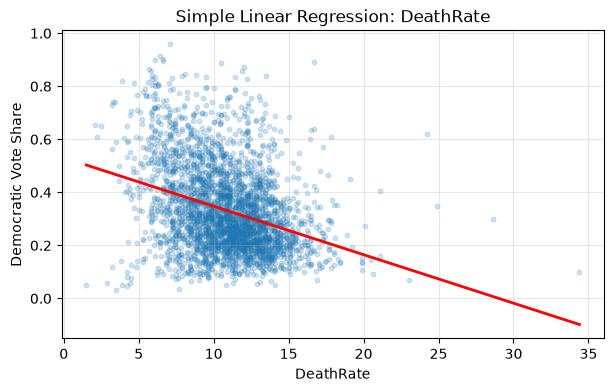


--- BachelorRate ---
Slope: 0.007862
P-value: 8.95163e-164
R-squared: 0.2128


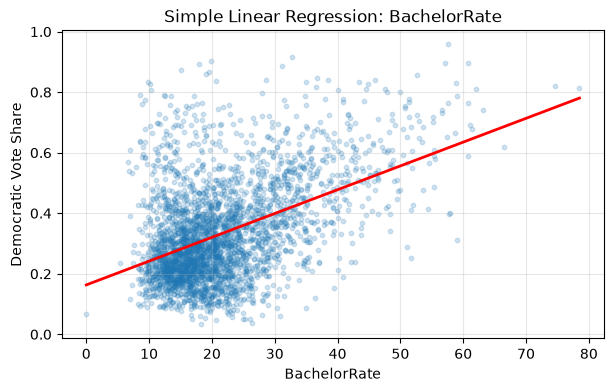


--- UnemploymentRate ---
Slope: 0.012438
P-value: 2.02586e-15
R-squared: 0.0201


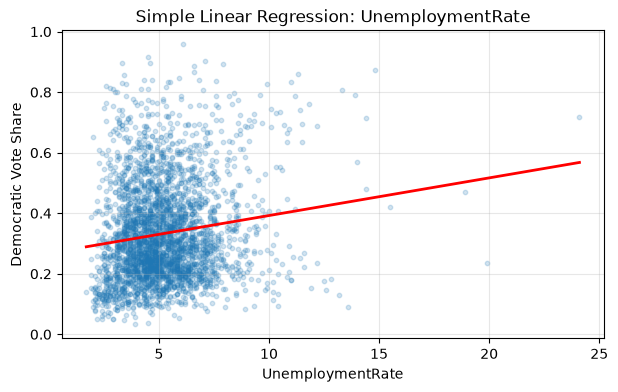


--- LogTotalVotes ---
Slope: 0.129884
P-value: 6.81673e-202
R-squared: 0.2560


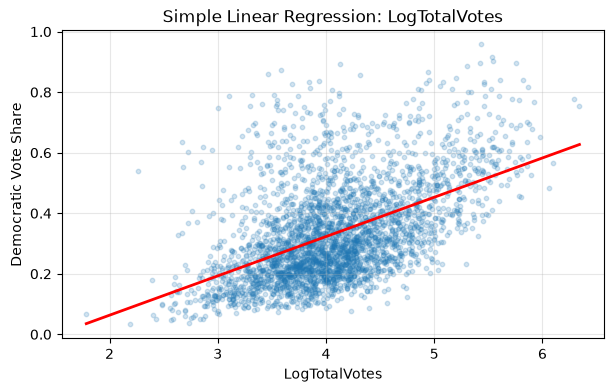

In [16]:
import statsmodels.api as sm

for predictor in predictors:
    X = sm.add_constant(df[[predictor]])
    y = df["DemShare"]

    model = sm.OLS(y, X).fit()

    print(f"\n--- {predictor} ---")
    print(f"Slope: {model.params[predictor]:.6f}")
    print(f"P-value: {model.pvalues[predictor]:.6g}")
    print(f"R-squared: {model.rsquared:.4f}")

    plt.figure(figsize=(7, 4))
    plt.scatter(df[predictor], y, alpha=0.2, s=10)

    # Fitted regression line
    x_sorted = df[predictor].sort_values()
    y_pred = model.params["const"] + model.params[predictor] * x_sorted

    plt.plot(x_sorted, y_pred, color="red", linewidth=2)

    plt.xlabel(predictor)
    plt.ylabel("Democratic Vote Share")
    plt.title(f"Simple Linear Regression: {predictor}")
    plt.grid(alpha=0.3)
    plt.show()

### 1(d) Simple Linear Regression Predictor Analysis

Seven simple linear regression models were fitted to investigate the relationship between each predictor and Democratic two-party vote share. For each model, the null hypothesis was H₀: β₁ = 0, tested against H₁: β₁ ≠ 0 at a significance level of α = 0.05.

Five predictors were statistically significant: MedianIncome, DeathRate, BachelorRate, UnemploymentRate, and LogTotalVotes. MigraRate (p = 0.0676) and BirthRate (p = 0.2188) were not statistically significant, so we failed to reject the null hypothesis for these two predictors.

LogTotalVotes had the highest R² value (0.2560), explaining approximately 25.60% of the variation in Democratic vote share. BachelorRate was the second strongest predictor, with R² = 0.2128, explaining approximately 21.28% of the variation.

DeathRate had a negative regression slope (-0.01828), indicating a negative linear association with Democratic vote share. The other predictors had positive slopes.

Although five predictors were statistically significant, several had relatively low R² values. This demonstrates that statistical significance does not necessarily imply strong explanatory power.

Overall, LogTotalVotes and BachelorRate were the strongest individual linear predictors of Democratic vote share among the variables examined.

## 1(e) Multiple Linear Regression

In [17]:
# Multiple linear regression with all seven predictors
X = sm.add_constant(df[predictors])
y = df["DemShare"]

model_full = sm.OLS(y, X).fit()

print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:               DemShare   R-squared:                       0.448
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     359.1
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:43:54   Log-Likelihood:                 2194.5
No. Observations:                3111   AIC:                            -4373.
Df Residuals:                    3103   BIC:                            -4325.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.0386      0.029  

### 1(e): Multiple Linear Regression Analysis

A multiple linear regression model was fitted using all seven predictors.

The null hypothesis is H₀: β₁ = β₂ = ⋯ = β₇ = 0, meaning none of the predictors have a linear effect on the response when considered together. The alternative hypothesis is that at least one coefficient is nonzero.

The model produced an F-statistic of 359.1 with a p-value below 0.001. Since the p-value is less than α = 0.05, we reject the null hypothesis.

The model has an R² of 0.448, meaning the seven predictors collectively explain approximately 44.8% of the variation in Democratic vote share across counties.

## 1(f): Two-predictor multiple regression

In [18]:
X_two = sm.add_constant(df[["LogTotalVotes", "BachelorRate"]])
y = df["DemShare"]

model_two = sm.OLS(y, X_two).fit()

print(model_two.summary())

                            OLS Regression Results                            
Dep. Variable:               DemShare   R-squared:                       0.311
Model:                            OLS   Adj. R-squared:                  0.311
Method:                 Least Squares   F-statistic:                     702.3
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          2.14e-252
Time:                        15:49:33   Log-Likelihood:                 1851.5
No. Observations:                3111   AIC:                            -3697.
Df Residuals:                    3108   BIC:                            -3679.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.1503      0.016     -9.378

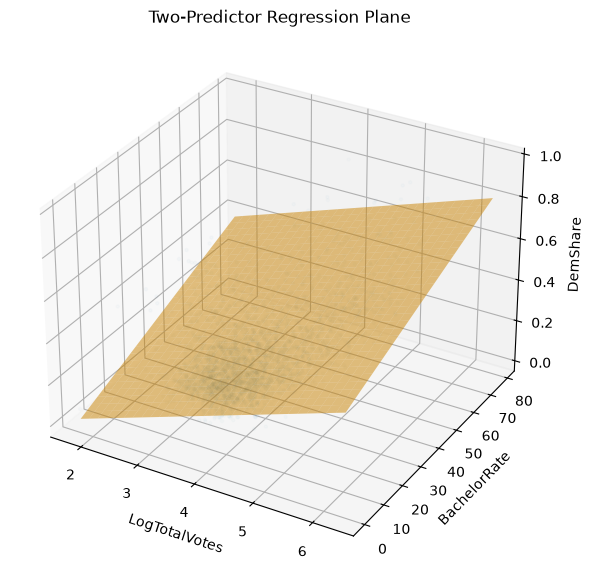

In [19]:
# Create values for the regression plane
x1 = np.linspace(df["LogTotalVotes"].min(),
                 df["LogTotalVotes"].max(), 30)

x2 = np.linspace(df["BachelorRate"].min(),
                 df["BachelorRate"].max(), 30)

X1, X2 = np.meshgrid(x1, x2)

# Calculate predicted values
Z = (model_two.params["const"]
     + model_two.params["LogTotalVotes"] * X1
     + model_two.params["BachelorRate"] * X2)

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot actual data
ax.scatter(
    df["LogTotalVotes"],
    df["BachelorRate"],
    df["DemShare"],
    alpha=0.15,
    s=5
)

# Plot regression plane
ax.plot_surface(X1, X2, Z, alpha=0.5, color="orange")

ax.set_xlabel("LogTotalVotes")
ax.set_ylabel("BachelorRate")
ax.set_zlabel("DemShare")
ax.set_title("Two-Predictor Regression Plane")

plt.show()

## 1(g)

## 1(h)

## Part 2 - Face Analysis